# Week 11A: Visualizing large spatial datasets

**Lecture guide:** Memory and lazy computation → OSM density → Census categories → Taxi activity over time → Parking exercise → Scaling up

This combines and revises **Visualizing Large Data-Lec1.ipynb** and **Visualizing Large Data-Lec2.ipynb**. We retain their main examples while removing duplicate code, absolute paths, whole-dataset conversions to pandas, and inconsistent CRS transformations.

[Download this notebook](lecture-11A.ipynb) · [Data provenance](data/samples/provenance.json) · [Companion LiDAR lesson](lecture-11B.html)

**Learning goals:** read partitioned data lazily, aggregate millions of records into a fixed-size image, compare color scales, aggregate categories, interpret spatial/time patterns, and export portable visualizations.

## Part 1: A manageable classroom workflow

The original sources contain about one billion OSM GPS points, 300 million historical Census dots, and 12 million taxi trips. Loading all three is unnecessary for learning the method.

This folder includes **real teaching extracts**: 1,000,050 OSM points, 1,533,372 Census dots, 150,000 taxi trips, and 10,000 parking records. They are systematically thinned teaching extracts, **not full datasets or validated representative samples**. Counts and patterns in these extracts must not be described as population totals or representative city statistics. Census dots are historical synthetic locations, not exact residents' addresses.

Use the bundled extracts by default. The last section explains how to switch to complete local datasets. Download the whole lab folder when working locally; the notebook needs `data/samples/`.

### Environment setup

Use [environment-viz.yml](environment-viz.yml) to create a separate environment from a terminal, then select that kernel:

```bash
conda env create -f environment-viz.yml
conda activate musa-largeviz
python -m ipykernel install --user --name musa-largeviz --display-name "Python (large spatial data)"
```

The environment file uses a tested compatible NumPy/Numba/Datashader stack. Do not force upgrades inside the running notebook. LiDAR has a separate environment because its native libraries have different dependencies.

In [1]:
from pathlib import Path
import base64
import io
import json
import os

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import datashader as ds
import datashader.transfer_functions as tf
from datashader.utils import lnglat_to_meters
from colorcet import fire
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, HTML, IFrame

# Works from this lab folder or from the repository root.
LAB = Path.cwd()
if not (LAB / "data/samples").is_dir():
    LAB = LAB / "public/labs/week11-large-data-viz-lidar"
DATA = LAB / "data/samples"
OUT = LAB / "outputs/viz"
OUT.mkdir(parents=True, exist_ok=True)
if not (DATA / "osm_sample.parquet").is_file():
    raise FileNotFoundError("Download the whole lab folder, including data/samples, first.")
print("Datashader", ds.__version__, "| Dask", dask.__version__)

Datashader 0.16.2 | Dask 2024.5.0


### What changes when data no longer fits in memory?

| Object | What it contains | When work happens |
| --- | --- | --- |
| pandas DataFrame | One in-memory table | Immediately |
| Dask DataFrame | A graph of partitioned table operations | Usually at `.compute()` or aggregation |
| Datashader aggregate | A fixed-size grid of pixel statistics | After scanning the input partitions |

Dask can process data larger than RAM, but not every operation is automatically memory-safe. Avoid converting the entire table to pandas or calling `.persist()` unless it fits in memory. A small scalar result such as a count is safe to compute; a billion-row table is not.

Datashader does **not** require EPSG:3857; it aggregates numeric coordinates. We use Web Mercator for these map examples because the source coordinates and common web basemaps use it.

## Part 2: OSM GPS points — from points to pixels

The source is the historical [OpenStreetMap bulk GPS release](https://blog.openstreetmap.org/2012/04/01/bulk-gps-point-data/), distributed as a Datashader example dataset. This measures uploaded GPS-trace activity, not all roads, all people, or an unbiased sample of travel.

Read only the two coordinate columns. Parquet row groups allow Dask to build useful partitions even when the extract is one file.

In [2]:
osm = dd.read_parquet(DATA / "osm_sample.parquet", columns=["x", "y"],
                      engine="pyarrow", split_row_groups=True)
print("Partitions:", osm.npartitions)
osm.head()

Partitions: 21


,x,y
0,-7000458.5,-9536415.0
1,-7141858.0,-9664043.0
2,-7379035.0,-9890349.0
3,-7721307.5,-10498321.0
4,-7514765.5,-7346013.0


### Lazy reductions

The expressions below are tasks until we compute them. A joint `dask.compute()` call lets related tasks share work. Counting all rows still requires scanning their partitions.

In [3]:
row_count, mean_x, mean_y = dask.compute(osm.shape[0], osm.x.mean(), osm.y.mean())
print(f"Extract rows: {row_count:,}; mean x={mean_x:,.0f}, y={mean_y:,.0f} meters")

Extract rows: 1,000,050; mean x=2,731,821, y=5,801,809 meters


### Coordinate ranges and the rendering pipeline

Do not divide meter coordinates by an arbitrary factor to pretend they are longitude/latitude. Convert a geographic bounding box with a real projection. For map overlays, all layers must use the same CRS.

**Project/choose extent → aggregate → transform/color → display.** [Datashader pipeline documentation](https://datashader.org/getting_started/Pipeline.html).

A scatter plot creates one marker per record, which can overplot badly. Matplotlib can handle many points; the issue is the cost and interpretability of drawing millions of individual markers. Datashader instead computes a pixel statistic.

In [4]:
def mercator_extent(lon_bounds, lat_bounds):
    x, y = lnglat_to_meters(lon_bounds, lat_bounds)
    return tuple(x), tuple(y)

world_x, world_y = mercator_extent((-180, 180), (-70, 80))
canvas = ds.Canvas(plot_width=900, plot_height=450, x_range=world_x, y_range=world_y)
osm_count = canvas.points(osm, "x", "y", agg=ds.count())
print("Aggregate dimensions:", dict(osm_count.sizes))
print("Points inside this extent:", int(osm_count.sum()))

Aggregate dimensions: {'y': 450, 'x': 900}
Points inside this extent: 1000049


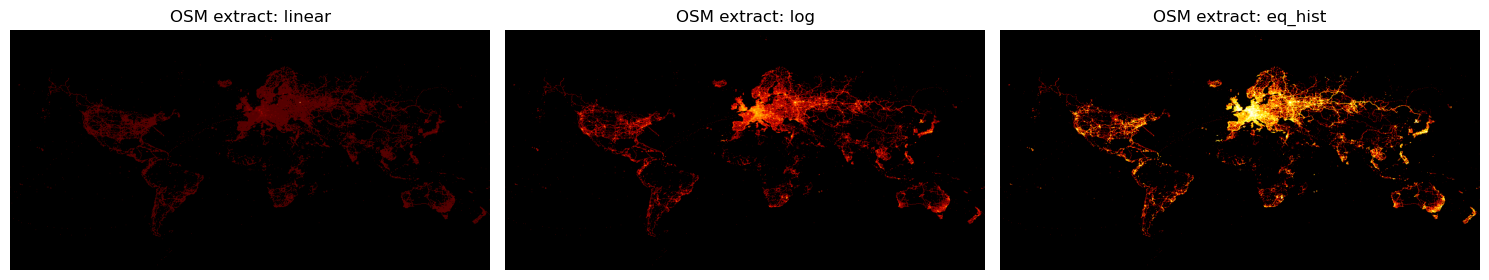

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, how in zip(axes, ["linear", "log", "eq_hist"]):
    image = tf.set_background(tf.shade(osm_count, cmap=fire[40:], how=how), "black")
    ax.imshow(image.to_pil())
    ax.set_title(f"OSM extract: {how}")
    ax.set_axis_off()
fig.tight_layout()
plt.show()

### Interpret color mapping carefully

- **Linear:** preserves direct visual differences but can hide sparse areas.
- **Log:** expands the lower end of a skewed distribution.
- **Equalized histogram:** improves contrast, but color differences are not proportional count differences.

Changing the color transform does not change the aggregate. Masking low-count pixels does change what is shown. Compare counts before deciding that a bright place is more active than another map drawn with a different scale.

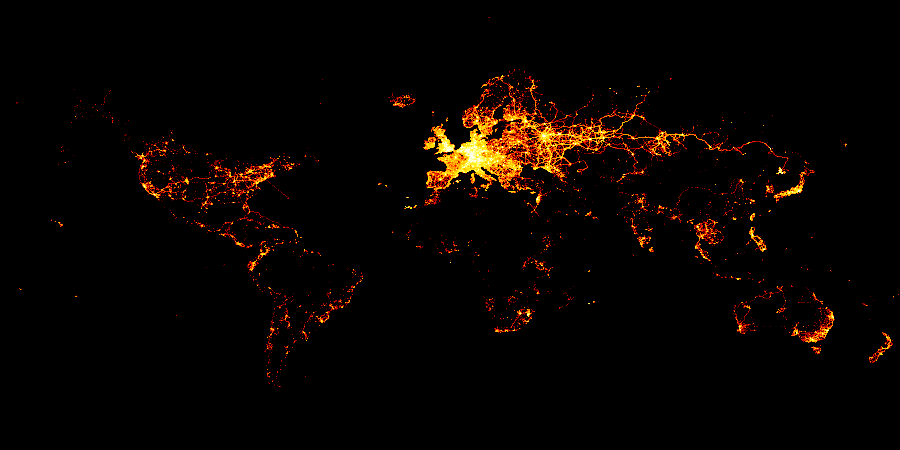

In [6]:
masked_osm = osm_count.where(osm_count > 2)
osm_image = tf.set_background(tf.shade(masked_osm, cmap=fire[40:], how="eq_hist"), "black")
osm_image.to_pil().save(OUT / "osm_density.png")
display(osm_image.to_pil())

## Part 3: Census dots — categories and geographic questions

These historical 2010 dots use `easting`/`northing` in EPSG:3857 and five encoded race/ethnicity categories. Set a **known categorical dtype** before a distributed category aggregation. This avoids scanning all records just to discover the category labels.

These categories reproduce the source dataset's encoding and are limited representations of demographic identity. Selected synthetic dots cannot establish neighborhood population totals, diversity, segregation, or gerrymandering.

In [7]:
race_labels = {"w": "White", "b": "Black", "a": "Asian", "h": "Hispanic", "o": "Other"}
color_key = {"w": "#4cc9f0", "b": "#ffb703", "a": "#90be6d", "h": "#f28482", "o": "#cdb4db"}
census = dd.read_parquet(DATA / "census_sample.parquet", split_row_groups=True)
census["race"] = census["race"].astype(pd.CategoricalDtype(list(race_labels)))
census.head()

,easting,northing,race
0,-12352377.0,3676244.50,h
1,-12352691.0,3679306.75,h
2,-12352058.0,3677210.50,h
3,-12352007.0,3680322.75,h
4,-12351758.0,3677555.75,h


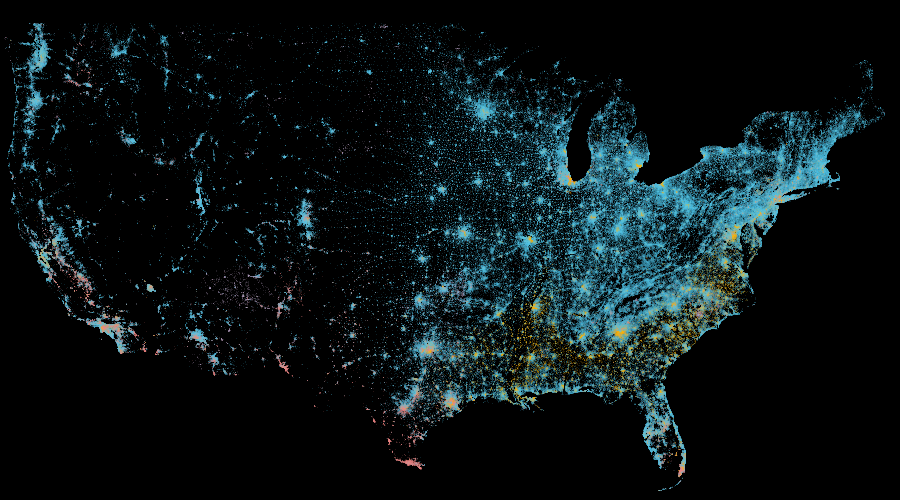

w       White
b       Black
a       Asian
h    Hispanic
o       Other
Name: Source category labels, dtype: object

In [8]:
usa_x, usa_y = mercator_extent((-125, -66), (24, 50))
census_canvas = ds.Canvas(plot_width=900, plot_height=500, x_range=usa_x, y_range=usa_y)
category_count = census_canvas.points(census, "easting", "northing", agg=ds.count_cat("race"))
census_image = tf.set_background(tf.shade(category_count, color_key=color_key, how="eq_hist"), "black")
display(census_image.to_pil())
pd.Series(race_labels, name="Source category labels")

### Slice the aggregate rather than reread the original points

The category dimension is an xarray coordinate. Ask where the extract has more Black than White dots, or where all four selected categories are present. These are **pixel-scale descriptive questions**; changing pixel size changes the answer. They are not validated demographic indices.

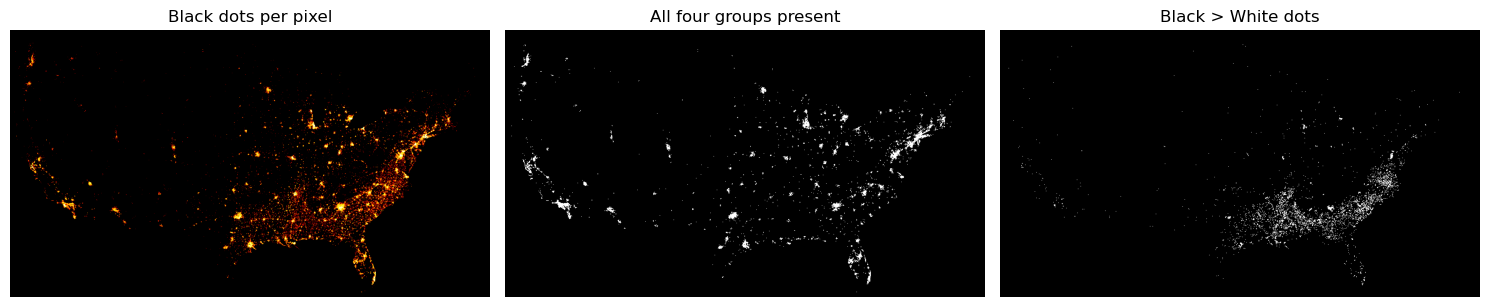

In [9]:
black_pixels = category_count.sel(race="b")
all_present = (category_count.sel(race=["w", "b", "a", "h"]) > 0).all(dim="race")
black_exceeds_white = category_count.sel(race="b") > category_count.sel(race="w")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, array, title in zip(axes, [black_pixels, all_present.astype("uint32"),
                                  black_exceeds_white.astype("uint32")],
                             ["Black dots per pixel", "All four groups present", "Black > White dots"]):
    ax.imshow(tf.set_background(tf.shade(array.where(array > 0), cmap=fire[40:]), "black").to_pil())
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

### Overlay a vector boundary in the same coordinate system

The bundled 2015 congressional boundaries preserve the historical overlay exercise from the source lectures. They are **not current districts**, and their date differs from the 2010 dots. The overlay teaches CRS alignment; it cannot by itself demonstrate discriminatory districting.

The GeoJSON coordinates are longitude/latitude. Project each ring before plotting it over the EPSG:3857 image.

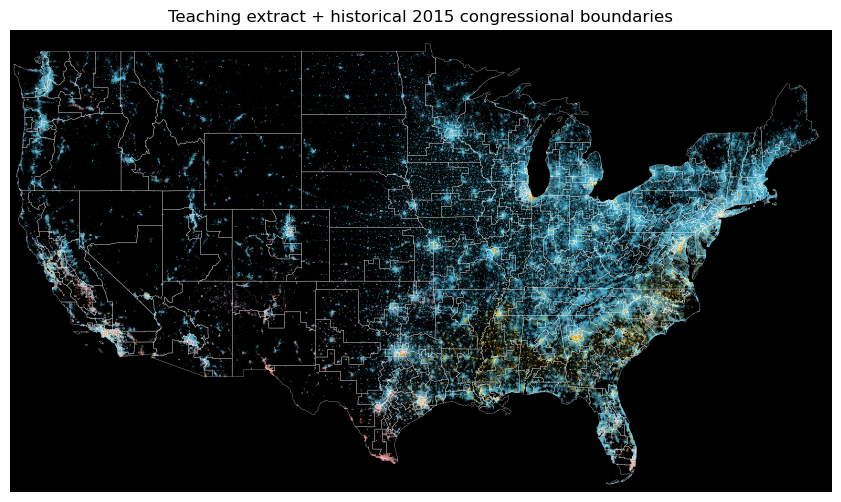

In [10]:
districts = json.loads((DATA / "districts_2015.geojson").read_text())
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(census_image.to_pil(), extent=[*usa_x, *usa_y], origin="upper")
for feature in districts["features"]:
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    for polygon in polygons:
        ring = np.asarray(polygon[0])
        x, y = lnglat_to_meters(ring[:, 0], ring[:, 1])
        ax.plot(x, y, color="white", linewidth=0.25, alpha=0.7)
ax.set(xlim=usa_x, ylim=usa_y, title="Teaching extract + historical 2015 congressional boundaries")
ax.set_axis_off()
plt.show()

## Part 4: NYC taxis — comparing origins, destinations, and time

The extract contains 150,000 real historical January 2015 trips. The source is the Datashader example Parquet file; timestamps were retained and hour fields reconstructed during preparation to avoid a legacy integer encoding problem.

Count **trips**, not passengers: `ds.count()` counts rows, while `ds.sum("passenger_count")` would sum passengers if that column were available. We do not infer whole-city demand from this bounded extract.

The pickup-minus-dropoff comparison uses a symmetric logarithmic color scale so small differences remain visible while retaining their sign.

In [11]:
taxi = dd.read_parquet(DATA / "taxi_sample.parquet", split_row_groups=True)
NYC_X, NYC_Y = mercator_extent((-74.10, -73.70), (40.60, 40.90))
taxi_canvas = ds.Canvas(plot_width=750, plot_height=550, x_range=NYC_X, y_range=NYC_Y)
pickups = taxi_canvas.points(taxi, "pickup_x", "pickup_y", agg=ds.count()).rename({"pickup_x": "x", "pickup_y": "y"})
dropoffs = taxi_canvas.points(taxi, "dropoff_x", "dropoff_y", agg=ds.count()).rename({"dropoff_x": "x", "dropoff_y": "y"})
print("In-view pickups:", int(pickups.sum()), "| in-view dropoffs:", int(dropoffs.sum()))

In-view pickups: 149998 | in-view dropoffs: 149994


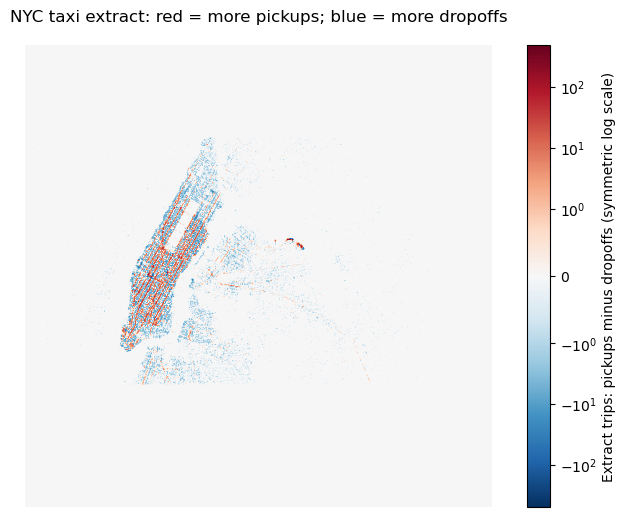

In [12]:
# Subtract signed values: unsigned subtraction would wrap below zero.
balance = pickups.astype("int64") - dropoffs.astype("int64")
from matplotlib.colors import SymLogNorm
limit = max(1, int(np.abs(balance).max()))
fig, ax = plt.subplots(figsize=(9, 6))
plot = ax.imshow(balance, origin="lower", cmap="RdBu_r", norm=SymLogNorm(linthresh=1, vmin=-limit, vmax=limit),
                 extent=[*NYC_X, *NYC_Y])
fig.colorbar(plot, ax=ax, label="Extract trips: pickups minus dropoffs (symmetric log scale)")
ax.set_title("NYC taxi extract: red = more pickups; blue = more dropoffs")
ax.set_axis_off()
plt.show()

### A calendar view from timestamps

Here we **do** compute a small grouped result, not the whole trip table. Weekday/hour counts describe only the extract's January 2015 coverage. The full-year 2016 holiday and blizzard claims in the original lecture cannot be transferred to this different sample.

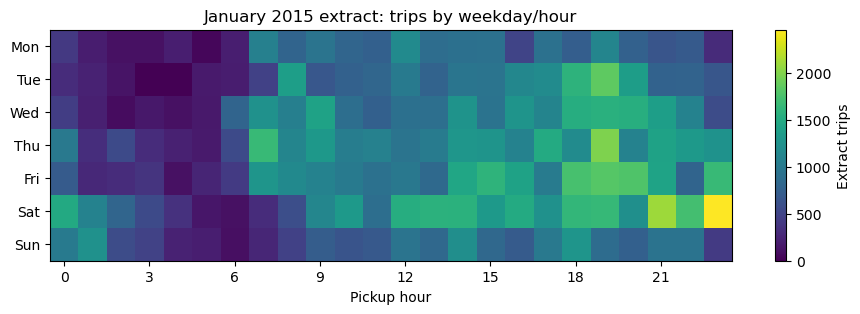

In [13]:
taxi["weekday"] = taxi.tpep_pickup_datetime.dt.dayofweek
hourly_table = taxi.groupby(["weekday", "pickup_hour"]).size().compute().unstack(fill_value=0)
hourly_table = hourly_table.reindex(index=range(7), columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3))
plot = ax.imshow(hourly_table, aspect="auto", cmap="viridis")
ax.set(yticks=range(7), yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
       xticks=range(0, 24, 3), xlabel="Pickup hour", title="January 2015 extract: trips by weekday/hour")
fig.colorbar(plot, ax=ax, label="Extract trips")
plt.show()

### Export a 24-hour animation

Precompute the hourly pixel counts once using a known categorical hour field. Use a **shared log count scale** for all frames so brightness remains comparable. A frame-by-frame equalized histogram would change the meaning of color each hour.

In [14]:
taxi["dropoff_hour"] = taxi["dropoff_hour"].astype(pd.CategoricalDtype(list(range(24))))
by_hour = taxi_canvas.points(taxi, "dropoff_x", "dropoff_y", agg=ds.count_cat("dropoff_hour"))
max_count = max(2, int(by_hour.max()))
frames = []
from PIL import ImageDraw
for hour in range(24):
    image = tf.set_background(tf.shade(by_hour.sel(dropoff_hour=hour), cmap=fire[40:],
                                       how="log", span=(1, max_count)), "black").to_pil().convert("RGB")
    ImageDraw.Draw(image).text((16, 16), f"{hour:02d}:00 | historical taxi extract", fill="white")
    frames.append(image)
frames[0].save(OUT / "taxi_dropoffs_24h.gif", save_all=True, append_images=frames[1:],
               duration=250, loop=0)
display(HTML('<img src="outputs/viz/taxi_dropoffs_24h.gif" alt="24-hour taxi drop-off animation">'))

### A slider that works in the published HTML

A live hvPlot/Datashader view can reaggregate points as you pan and zoom, but that requires an active Python kernel or Panel server. Saving a dynamic Python callback in a static page does not make it work without Python.

For this course's static website, embed the **24 precomputed frames** in a Bokeh document. The JavaScript slider works without a Python server. Zooming enlarges the precomputed image; it does not rescan the original points. Bokeh's JavaScript is embedded too, so this slider does not depend on a CDN.

In [15]:
from bokeh.embed import file_html
from bokeh.resources import INLINE
from bokeh.layouts import column
from bokeh.models import ColumnDataSource, CustomJS, Slider
from bokeh.plotting import figure

frame_urls = []
for frame in frames:
    buffer = io.BytesIO()
    frame.save(buffer, format="PNG")
    frame_urls.append("data:image/png;base64," + base64.b64encode(buffer.getvalue()).decode())
source = ColumnDataSource(dict(url=[frame_urls[0]]))
plot = figure(width=800, height=580, x_range=(0, 1), y_range=(0, 1),
              title="Taxi dropoffs by hour — precomputed extract", tools="pan,wheel_zoom,reset,save")
plot.image_url(url="url", source=source, x=0, y=1, w=1, h=1, anchor="top_left")
plot.axis.visible = False
slider = Slider(start=0, end=23, value=0, step=1, title="Hour of day")
slider.js_on_change("value", CustomJS(args=dict(source=source, frames=frame_urls),
    code="source.data.url = [frames[cb_obj.value]]; source.change.emit();"))
(OUT / "taxi_hour_slider.html").write_text(file_html(column(slider, plot), INLINE, "Taxi hour explorer"))
display(IFrame("outputs/viz/taxi_hour_slider.html", width=850, height=680))

## Part 5: Guided exercise — Philadelphia parking records

The source lecture used [this public parking-violations CSV](https://musa550.s3.amazonaws.com/parking_violations.csv). Our small extract retains its `lat`/`lon` columns. It contains missing locations, so drop missing values **only in the coordinate columns**, then reject impossible coordinates.

**Try first:** read lazily, clean locations, convert to EPSG:3857 partition by partition, and render counts on a Philadelphia canvas. Compare `dropna()` on every field with coordinate-only filtering.

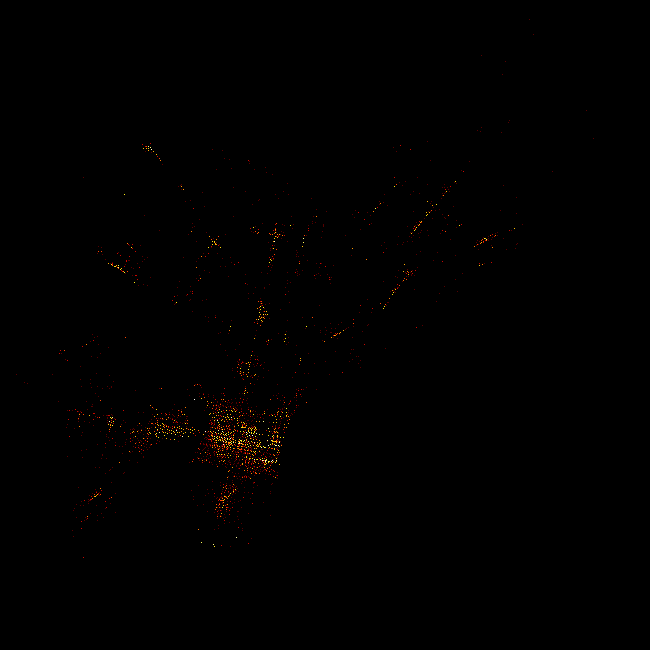

In [16]:
parking = dd.read_csv(DATA / "parking_sample.csv", dtype={"lat": "float64", "lon": "float64"})
parking = parking.dropna(subset=["lat", "lon"])
parking = parking[parking.lat.between(-85, 85) & parking.lon.between(-180, 180)]

def project_parking(partition):
    result = partition.copy()
    result["x"], result["y"] = lnglat_to_meters(result.lon.to_numpy(), result.lat.to_numpy())
    return result

meta = parking._meta.assign(x=pd.Series(dtype="float64"), y=pd.Series(dtype="float64"))
parking_xy = parking.map_partitions(project_parking, meta=meta)
philly_x, philly_y = mercator_extent((-75.28, -74.96), (39.86, 40.14))
parking_canvas = ds.Canvas(plot_width=650, plot_height=650, x_range=philly_x, y_range=philly_y)
parking_counts = parking_canvas.points(parking_xy, "x", "y", agg=ds.count())
parking_image = tf.set_background(tf.shade(parking_counts, cmap=fire[40:], how="eq_hist"), "black")
display(parking_image.to_pil())

## Part 6: Scale from the extract to the full dataset

Use a local Parquet path or directory, select only needed columns, and let Dask scan partitions. Do not read every Parquet file into pandas and concatenate it before creating Dask: that defeats out-of-core processing.

Original download sources:

- [OSM GPS archive](https://s3.amazonaws.com/datashader-data/osm-1billion.snappy.parq.zip)
- [2010 Census dots](https://s3.amazonaws.com/datashader-data/census2010.parq.zip)
- [Historical taxi trips](https://s3.amazonaws.com/datashader-data/nyc_taxi_wide.parq)

These are optional, large downloads. The sample workflow does not download them automatically. The old taxi Parquet has legacy integer encodings; use the prepared modern extract unless you have separately converted the archive. Reproject using CRS-aware formulas, never arbitrary multiplication/division.

In [17]:
# Optional: set OSM_PARQUET to your complete local dataset before starting Jupyter.
full_osm_path = os.environ.get("OSM_PARQUET")
if full_osm_path:
    full_osm = dd.read_parquet(full_osm_path, columns=["x", "y"], split_row_groups=True)
    print("Full dataset partitions:", full_osm.npartitions)
    # This next operation scans the complete dataset. Uncomment deliberately:
    # full_count = canvas.points(full_osm, "x", "y", agg=ds.count())
else:
    print("Using bundled extracts. Full archives are optional.")

Using bundled extracts. Full archives are optional.


## Wrap-up

- Input records may be huge; the aggregate size depends on pixels and categories.
- Sampling, filtering, CRS, binning resolution, and color transforms all affect interpretation.
- Use lazy reads, bounded computations, and explicit units.
- A static HTML visualization can offer JavaScript interactions; live reaggregation needs Python.

**Exercises:** double the canvas resolution; compare shared versus independent color scales; add a morning-versus-evening taxi comparison; and explain why a selected GPS extract cannot measure population density.

**Source material:** `Visualizing Large Data-Lec1.ipynb` and `Visualizing Large Data-Lec2.ipynb`, consolidated and corrected for this lab. The original notebooks are retained locally; their large embedded outputs are not required for this lesson.